# 2. Cell Cycle Timing & Scanning c-MYC (Norris *et al.* Figure 1E)

In Chapter 1, we modelled how **BCL2** delays or blocks programmed cell death (**Figure 1B** of *Norris et al.*, 2024). Now we model the second cell-fate clock: the **37-species Cell Cycle ODE model**, scanning **c-MYC** overexpression (`1×` to `100×`) to recreate **Figure 1E** of *Norris et al.* (*Blood Cancer Journal*, 2024).

## Clinical Context: c-MYC Overexpression & G1 Shortening

- ***MYC* translocations (`t(8;14)`) and overexpression** are the defining genetic hallmark of **Burkitt lymphoma** (one of the fastest-growing human tumours) and occur in ~10–15% of DLBCL.
- **c-MYC** is a master transcription factor that boosts ribosome biogenesis and protein growth machinery (`GM`), allowing cells to reach the size and biochemical threshold needed to pass the **G1/S restriction point** sooner.
- **Double-Hit Lymphoma (`MYC` + `BCL2`):** High c-MYC alone often triggers stress-induced apoptosis in healthy cells. When a lymphoma cell *also* overexpresses **BCL2** (Chapter 1), it bypasses that safety net — combining rapid G1-shortened proliferation with resistance to cell death.
- **Clinical drug targets in G1:** Drugs such as **CDK4/6 inhibitors** (e.g. **palbociclib**) act specifically on the **Cyclin D–CDK4/6–RB1** G1/S checkpoint, while loss-of-function mutations in the tumour suppressors **`RB1`** or **`CDKN1B` (p27)** remove the brakes on G1 entry.

---

## How the Cell Cycle Model Works (and What Callbacks Do!)

```{figure} ../images/cell-cycle-pathway.svg
:alt: Cell cycle phases G1, S, G2, M and regulation by c-MYC, Cyclins, RB1, E2F, and p27, with mitotic mass halving into two daughter cells
:width: 100%

The four phases of the cell cycle (**G1 → S → G2 → M**). **c-MYC** accelerates cell growth (`GM` and `Mass`) in **G1**, while **p27** and **RB1** act as G1/S brakes. At the end of **M**, mitosis halves `Mass` and `GM` (`0.5×`) as two daughter cells begin a fresh G1 phase.
```

Unlike the NF-κB and apoptosis models, a proliferating cell does **not** settle to a flat constant concentration — it **oscillates repeatedly** through **G1 → S → G2 → M**, dividing into two daughter cells at the end of every cycle.

To represent cell division inside an ODE solver, `DifferentialEquations.jl` uses a **`ContinuousCallback`**:
- Think of a callback as a **tripwire** monitored continuously while the solver runs.
- Every time a specific biological condition crosses zero, the solver pauses at that exact instant, executes a short rule (an `affect!` function), and continues integrating.
- Our cell-cycle model uses three callbacks:
  1. **Mitotic division (`cond_cdh1`):** When `Cdh1` rises past `0.2` at the end of mitosis, the cell divides — **`Mass`** and growth machinery **`GM`** are instantaneously multiplied by **`0.5`**! The callback also records the last 5 post-division masses; once 5 consecutive divisions are identical (meaning the cell has converged to a stable repeating **limit cycle**), it calls `terminate!(integrator)` so we don't waste time simulating further.
  2. **RB restriction-point switch (`cond_rb`):** Toggles `r31switch` when phosphorylated RB crosses 80%.
  3. **Low-mass arrest switch (`cond_mass`):** Toggles `newSwitch` if `Mass` drops below `0.5`.

---

## Step 1: Build the 37-Species Cell Cycle Model in `scan` Mode

Run the cell below to generate `odeCellCycle.jl` from `cellCycle/` in `scan` mode so we can sweep `modify["k1_myc"]` and test G1 rescue targets at run-time.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()

# Generate the 37-species Cell Cycle ODE model in "scan" mode
run(`python3 csv2model-multiscale.py cellCycle/reactions_cellCycle.csv cellCycle/parameters_cellCycle.csv cellCycle/rateLaws_cellCycle.csv odeCellCycle.jl scan`)

odeCCFun = include("odeCellCycle.jl")
include("variableNames.jl")
include("scanIncludes.jl")

println("Cell Cycle model ready: ", length(syms), " species, ", length(parameterList), " parameters.")

scan
Running CSV2JuliaDiffEq with parameters left as a function call to paramFun(n), for all params. We will also create a paramFun.jl file that should be included and defines all parameters. If this is incorrect, please re-run with 5th argument set to 'inline' or 'param'
Opening cellCycle/rateLaws_cellCycle.csv as rate law file
Opening cellCycle/parameters_cellCycle.csv as parameters file
Opening cellCycle/reactions_cellCycle.csv as reactions file


parameters can now be modified by name.
example to modify k_binding 1.5 fold higher:
modify["k_binding"]=1.5
Cell Cycle model ready: 37 species, 82 parameters.


---

## Step 2: Set Up Division Callbacks & Phase-Duration Detector

Next, we define:
- The three `ContinuousCallback` biological events (`cc_cbs`).
- `measure_phases(t_lc, mat_lc)` — extracts the duration (in minutes) of **G1**, **S**, **G2**, and **M** from the final converged division cycle:
  - **G1 → S:** `Cdh1` drops below 50% of its peak.
  - **S → G2:** `CycA` reaches 97.5% of its post-G1/S maximum.
  - **G2 → M:** `CycB` hits its mitotic peak.
  - **End of M:** The mitotic division event (`Cdh1` rising past `0.2`).
  - If a strong perturbation stops the cell from dividing altogether, `measure_phases` cleanly reports `arrested = true`.
- `run_cell_cycle(myc_mult; mods=Dict(...))` — runs any `k1_myc` multiplier plus optional gene modifications.

In [2]:
const f_cc = ODEFunction(odeCCFun)
const maxTimeSS_cc = 100000.0

const idx_Mass   = findfirst(isequal("Mass"), syms)
const idx_GM     = findfirst(isequal("GM"), syms)
const idx_NewSw  = findfirst(isequal("newSwitch"), syms)
const idx_Rb     = findfirst(isequal("Rb"), syms)
const idx_E2FRb  = findfirst(isequal("E2F_Rb"), syms)
const idx_pE2FRb = findfirst(isequal("pE2F_Rb"), syms)
const idx_HypoRb = findfirst(isequal("HypoP_Rb"), syms)
const idx_r31Sw  = findfirst(isequal("r31switch"), syms)
const idx_Cdh1   = findfirst(isequal("Cdh1"), syms)
const idx_cycE   = findfirst(isequal("cycE"), syms)
const idx_cycA   = findfirst(isequal("cycA"), syms)
const idx_cycB   = findfirst(isequal("cycB"), syms)
const idx_cycD   = findfirst(isequal("cycD"), syms)

const idx_MT1 = findfirst(isequal("previousMass1"), syms)
const idx_MT2 = findfirst(isequal("previousMass2"), syms)
const idx_MT3 = findfirst(isequal("previousMass3"), syms)
const idx_MT4 = findfirst(isequal("previousMass4"), syms)
const idx_MT5 = findfirst(isequal("previousMass5"), syms)
const idx_MTT1 = findfirst(isequal("previousMassTime1"), syms)
const idx_MTT2 = findfirst(isequal("previousMassTime2"), syms)
const idx_MTT3 = findfirst(isequal("previousMassTime3"), syms)
const idx_MTT4 = findfirst(isequal("previousMassTime4"), syms)
const idx_MTT5 = findfirst(isequal("previousMassTime5"), syms)

# Callback 1: RB restriction-point switch
function cond_rb(u, t, integrator)
    num = u[idx_Rb] + u[idx_E2FRb] + u[idx_pE2FRb]
    den = num + u[idx_HypoRb]
    return (num / max(den, 1e-12)) - 0.8
end
aff_rb_pos!(integrator) = (integrator.u[idx_r31Sw] = 0.0)
aff_rb_neg!(integrator) = (integrator.u[idx_r31Sw] = 1.0)

# Callback 2: Mitotic division when Cdh1 crosses 0.2 upwards
cond_cdh1(u, t, integrator) = u[idx_Cdh1] - 0.2
function aff_cdh1!(integrator)
    integrator.u[idx_Mass] *= 0.5
    integrator.u[idx_GM]   *= 0.5
    integrator.u[idx_NewSw] = integrator.u[idx_Mass] < 0.5 ? 0.0 : 1.0

    # Track the last 5 division masses & timestamps; stop once limit cycle converges
    integrator.u[idx_MT5]  = integrator.u[idx_MT4]
    integrator.u[idx_MT4]  = integrator.u[idx_MT3]
    integrator.u[idx_MT3]  = integrator.u[idx_MT2]
    integrator.u[idx_MT2]  = integrator.u[idx_MT1]
    integrator.u[idx_MT1]  = round(integrator.u[idx_Mass], digits=3)

    integrator.u[idx_MTT5] = integrator.u[idx_MTT4]
    integrator.u[idx_MTT4] = integrator.u[idx_MTT3]
    integrator.u[idx_MTT3] = integrator.u[idx_MTT2]
    integrator.u[idx_MTT2] = integrator.u[idx_MTT1]
    integrator.u[idx_MTT1] = integrator.t

    peaks = (integrator.u[idx_MT5], integrator.u[idx_MT4], integrator.u[idx_MT3],
             integrator.u[idx_MT2], integrator.u[idx_MT1])
    if peaks[1] > 0.0 && all(==(peaks[1]), peaks)
        terminate!(integrator)
    end
end

# Callback 3: Minimum mass growth switch
cond_mass(u, t, integrator) = u[idx_Mass] - 0.5
aff_mass_pos!(integrator) = (integrator.u[idx_NewSw] = 1.0)
aff_mass_neg!(integrator) = (integrator.u[idx_NewSw] = 0.0)

const cc_cbs = CallbackSet(
    ContinuousCallback(cond_rb, aff_rb_pos!, aff_rb_neg!),
    ContinuousCallback(cond_cdh1, aff_cdh1!, nothing),
    ContinuousCallback(cond_mass, aff_mass_pos!, aff_mass_neg!),
)

function initConditionsCellCycle(syms, myc=40.0)
    y0 = zeros(length(syms))
    inits = Dict(
        "ERG" => 0.0121809, "p27_cycA_Cdk2" => 0.0356927, "p27" => 0.00922806,
        "Cdc20" => 0.00220177, "p27_cycE_Cdk2" => 0.000542587, "cycE" => 0.0229112,
        "cycA" => 1.4094, "cycB" => 2.72898, "p27_cycD_Cdk2" => 0.010976,
        "cycD" => 0.43929, "Cdh1" => 0.000653278, "DRG" => 0.900533,
        "PPX" => 1.0, "IEP" => 0.154655, "Cdc20t" => 2.36733,
        "E2F_Rb" => 0.00478911, "E2F" => 0.989986, "HypoP_Rb" => 9.97574,
        "pE2F_Rb" => 0.0192822, "pE2F" => 3.98594, "GM" => 1.35565,
        "r31switch" => 1.0, "cMyc" => Float64(myc), "Mass" => 1.0,
        "newSwitch" => 1.0, "Rb" => 0.0, "cMyct" => 40.0,
    )
    for (k, v) in inits
        idx = findfirst(isequal(k), syms)
        if !isnothing(idx)
            y0[idx] = v
        end
    end
    return y0
end

const cc_alg = if isdefined(Main, :AutoFiniteDiff)
    AutoTsit5(Rosenbrock23(autodiff=AutoFiniteDiff()))
elseif isdefined(DifferentialEquations, :AutoFiniteDiff)
    AutoTsit5(Rosenbrock23(autodiff=DifferentialEquations.AutoFiniteDiff()))
else
    AutoTsit5(Rosenbrock23())
end

function measure_phases(t_lc::Vector{Float64}, mat_lc::Matrix{Float64})
    cdh1 = mat_lc[idx_Cdh1, :]
    cyca = mat_lc[idx_cycA, :]
    cycb = mat_lc[idx_cycB, :]

    max_cdh1 = maximum(cdh1)
    i_hi = findfirst(x -> x > 0.95 * max_cdh1, cdh1)
    isnothing(i_hi) && return (G1=NaN, S=NaN, G2=NaN, M=NaN, total=NaN, G1S=NaN, SG2=NaN, G2M=NaN, arrested=true)
    i_drop_rel = findfirst(x -> x < 0.5 * max_cdh1, @view cdh1[i_hi:end])
    isnothing(i_drop_rel) && return (G1=NaN, S=NaN, G2=NaN, M=NaN, total=NaN, G1S=NaN, SG2=NaN, G2M=NaN, arrested=true)
    i_g1s = min(i_hi + i_drop_rel - 1, length(t_lc))
    t_g1s = round(t_lc[i_g1s])

    max_cyca = maximum(@view cyca[i_g1s:end])
    i_sg2 = findfirst(x -> x > 0.975 * max_cyca, cyca)
    isnothing(i_sg2) && return (G1=NaN, S=NaN, G2=NaN, M=NaN, total=NaN, G1S=NaN, SG2=NaN, G2M=NaN, arrested=true)
    t_sg2 = round(t_lc[i_sg2])

    max_cycb = maximum(@view cycb[i_sg2:end])
    i_g2m = findfirst(x -> x == max_cycb, cycb)
    isnothing(i_g2m) && return (G1=NaN, S=NaN, G2=NaN, M=NaN, total=NaN, G1S=NaN, SG2=NaN, G2M=NaN, arrested=true)
    t_g2m = round(t_lc[i_g2m])

    t_total = round(t_lc[end])
    return (
        G1 = t_g1s,
        S  = t_sg2 - t_g1s,
        G2 = t_g2m - t_sg2,
        M  = t_total - t_g2m,
        total = t_total,
        G1S = t_g1s, SG2 = t_sg2, G2M = t_g2m,
        arrested = false,
    )
end

function run_cell_cycle(myc_mult::Real; mods::Dict{String, <:Real}=Dict{String, Float64}())
    for k in keys(modify)
        modify[k] = 1.0
    end
    modify["k1_myc"] = Float64(myc_mult)
    for (k, v) in mods
        if !haskey(modify, k)
            error("Parameter '$(k)' not found in modify! Check the Cell Cycle Target Genes table.")
        end
        modify[k] = Float64(v)
    end

    y0 = initConditionsCellCycle(syms, 40.0)
    sol = solve(ODEProblem(f_cc, y0, (0.0, maxTimeSS_cc)), cc_alg;
                callback=cc_cbs, abstol=1e-5, reltol=1e-3, saveat=1.0)

    sol_mat = Float64.(reduce(hcat, sol.u))
    t_prev2 = sol_mat[idx_MTT2, end]
    if t_prev2 <= 0.0
        return (
            t_hours = sol.t ./ 60.0,
            mat_lc  = sol_mat,
            phases  = (G1=NaN, S=NaN, G2=NaN, M=NaN, total=NaN, G1S=NaN, SG2=NaN, G2M=NaN, arrested=true),
        )
    end

    start_idx = findfirst(x -> x > t_prev2, sol.t)
    t_lc   = sol.t[start_idx:end] .- sol.t[start_idx]
    mat_lc = sol_mat[:, start_idx:end]
    phases = measure_phases(t_lc, mat_lc)
    return (t_hours = t_lc ./ 60.0, mat_lc = mat_lc, phases = phases)
end

println("Cell cycle simulation helper run_cell_cycle(myc_mult; mods=Dict(...)) ready.")

Cell cycle simulation helper run_cell_cycle(myc_mult; mods=Dict(...)) ready.


---

## Step 3: Recreate Figure 1E (Top) — WT vs MYC × 1.5 Across G1, S, G2, and M

Run the cell below to plot one converged division cycle for **WT (solid lines)** vs **MYC × 1.5 (dashed lines)** overlaid on the shaded **G1, S, G2, and M** phase intervals. Watch how the dashed **MYC × 1.5** curves shift left during **G1** (`Cdh1` drops earlier and `CycE`/`CycA` rise earlier), completing the division cycle sooner.

WT phase durations (mins):        G1=302.0, S=285.0, G2=102.0, M=41.0  (Total = 730.0 min)
MYC × 1.5 phase durations (mins): G1=294.0, S=285.0, G2=100.0, M=42.0  (Total = 721.0 min)


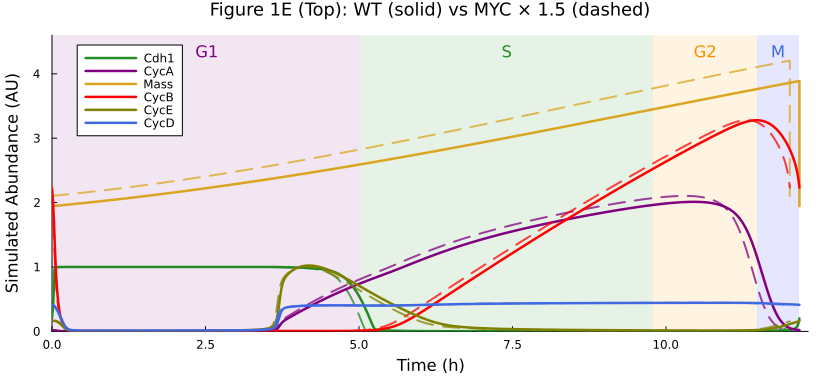

In [3]:
cc_wt  = run_cell_cycle(1.0)
cc_myc = run_cell_cycle(1.5)

println("WT phase durations (mins):        G1=$(cc_wt.phases.G1), S=$(cc_wt.phases.S), G2=$(cc_wt.phases.G2), M=$(cc_wt.phases.M)  (Total = $(cc_wt.phases.total) min)")
println("MYC × 1.5 phase durations (mins): G1=$(cc_myc.phases.G1), S=$(cc_myc.phases.S), G2=$(cc_myc.phases.G2), M=$(cc_myc.phases.M)  (Total = $(cc_myc.phases.total) min)")

p_e_top = plot(
    xlabel="Time (h)", ylabel="Simulated Abundance (AU)",
    title="Figure 1E (Top): WT (solid) vs MYC × 1.5 (dashed)", titlefontsize=12,
    xlims=(0, cc_wt.phases.total / 60.0 + 0.15),
    ylims=(0, 4.6),
    grid=false,
    size=(820, 390),
    legend=:topleft,
)

# Shaded WT G1, S, G2, M intervals
g1_end = cc_wt.phases.G1S / 60.0
s_end  = cc_wt.phases.SG2 / 60.0
g2_end = cc_wt.phases.G2M / 60.0
m_end  = cc_wt.phases.total / 60.0
vspan!(p_e_top, [0.0, g1_end],    color=:purple, alpha=0.10, label=false)
vspan!(p_e_top, [g1_end, s_end],  color=:green,  alpha=0.10, label=false)
vspan!(p_e_top, [s_end, g2_end],  color=:orange, alpha=0.12, label=false)
vspan!(p_e_top, [g2_end, m_end],  color=:blue,   alpha=0.10, label=false)

annotate!(p_e_top, g1_end / 2,            4.35, text("G1", 11, :purple))
annotate!(p_e_top, (g1_end + s_end) / 2,  4.35, text("S",  11, :forestgreen))
annotate!(p_e_top, (s_end + g2_end) / 2,  4.35, text("G2", 11, :darkorange))
annotate!(p_e_top, (g2_end + m_end) / 2,  4.35, text("M",  11, :royalblue))

for (lab, idx, col) in [
    ("Cdh1", idx_Cdh1, :forestgreen),
    ("CycA", idx_cycA, :purple),
    ("Mass", idx_Mass, :goldenrod),
    ("CycB", idx_cycB, :red),
    ("CycE", idx_cycE, :olive),
    ("CycD", idx_cycD, :royalblue),
]
    plot!(p_e_top, cc_wt.t_hours,  cc_wt.mat_lc[idx, :],  color=col, lw=2.5, linestyle=:solid, label=lab)
    plot!(p_e_top, cc_myc.t_hours, cc_myc.mat_lc[idx, :], color=col, lw=2.0, linestyle=:dash,  alpha=0.75, label=false)
end

p_e_top

---

## Step 4: Recreate Figure 1E (Bottom) — Scanning c-MYC (`1×` to `100×`)

Now scan **c-MYC** across `[1, 1.5, 2, 5, 10, 50, 100]` and plot the duration (in minutes) of **G1**, **S**, **G2**, and **M** side by side. Notice that **G1 drops steeply** as c-MYC increases, while **S**, **G2**, and **M** stay almost constant — matching experimental measurements of MYC-driven lymphomas!

Row,MYC,G1,S,G2,M,Total
,Float64,Float64,Float64,Float64,Float64,Float64
1,1.0,302.0,285.0,102.0,41.0,730.0
2,1.5,294.0,285.0,100.0,42.0,721.0
3,2.0,291.0,285.0,100.0,42.0,718.0
4,5.0,288.0,285.0,100.0,42.0,715.0
5,10.0,288.0,285.0,100.0,42.0,715.0
6,50.0,287.0,286.0,100.0,41.0,714.0
7,100.0,288.0,286.0,99.0,42.0,715.0


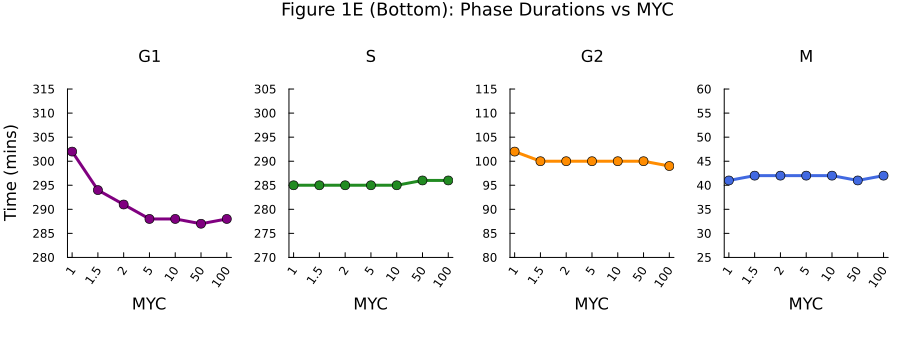

In [4]:
myc_mults = [1.0, 1.5, 2.0, 5.0, 10.0, 50.0, 100.0]
phase_df = DataFrame(MYC=Float64[], G1=Float64[], S=Float64[], G2=Float64[], M=Float64[], Total=Float64[])

for m in myc_mults
    ph = run_cell_cycle(m).phases
    push!(phase_df, (m, ph.G1, ph.S, ph.G2, ph.M, ph.total))
end

display(phase_df)

xt = ["1", "1.5", "2", "5", "10", "50", "100"]
xs = 1:length(myc_mults)

p_g1 = plot(xs, phase_df.G1, lw=3, marker=:circle, ms=5, color=:purple,
            xticks=(xs, xt), xrotation=55, ylims=(280, 315), title="G1", titlefontsize=11,
            ylabel="Time (mins)", legend=false, grid=false)
p_s  = plot(xs, phase_df.S,  lw=3, marker=:circle, ms=5, color=:forestgreen,
            xticks=(xs, xt), xrotation=55, ylims=(270, 305), title="S",  titlefontsize=11,
            legend=false, grid=false)
p_g2 = plot(xs, phase_df.G2, lw=3, marker=:circle, ms=5, color=:darkorange,
            xticks=(xs, xt), xrotation=55, ylims=(80, 115),  title="G2", titlefontsize=11,
            legend=false, grid=false)
p_m  = plot(xs, phase_df.M,  lw=3, marker=:circle, ms=5, color=:royalblue,
            xticks=(xs, xt), xrotation=55, ylims=(25, 60),   title="M",  titlefontsize=11,
            legend=false, grid=false)

plot(p_g1, p_s, p_g2, p_m, layout=(1, 4), size=(900, 340),
     plot_title="Figure 1E (Bottom): Phase Durations vs MYC",
     plot_titlefontsize=12, plot_titlevspan=0.14,
     top_margin=3Plots.mm, bottom_margin=4Plots.mm,
     xlabel="MYC")

---

## Interactive Exercises

### Exercise 1: Rescue MYC-Driven G1 Shortening (`MYC × 2.0`)

In a `MYC × 2.0` cell, **G1** shortens relative to wild-type (`302 min` → `291 min`), speeding up division. Below is a reference table of clinically relevant cell-cycle targets in the model:

| Gene / Protein | Role in Cell Cycle | Parameter Name in `modify` | Direction to Slow G1 |
| :--- | :--- | :--- | :--- |
| **p27 (`CDKN1B`)** | CDK inhibitor tumour suppressor (G1/S brake) | `"k2_5"` | Over-express (e.g. `1.1` – `1.5`) |
| **Cyclin D (`cycD`)** | G1 driver activating CDK4/6 *(palbociclib pathway)* | `"k2_9"` | Inhibit (e.g. `0.6` – `0.9`) |
| **RB phosphorylation** | CDK4/6/2 phosphorylation releasing E2F from RB1 | `"k1_20"` | Inhibit (e.g. `0.6` – `0.9`) |
| **RB1–E2F binding** | Tumour suppressor holding E2F inactive in G1 | `"k1_26"` | Boost (e.g. `1.2` – `2.0`) |
| **Growth machinery (`GM`)** | Ribosome biogenesis directly driven by c-MYC | `"k1_GMprod"` | Inhibit (e.g. `0.8` – `0.9`) |
| **Cyclin E (`cycE`)** | G1/S transition cyclin | `"k3_7"` | Inhibit (e.g. `0.6` – `0.9`) |
| **Cyclin A (`cycA`)** | S-phase progression cyclin | `"k2_29"` | Inhibit (e.g. `0.6` – `0.8`) |
| **Cyclin B (`cycB`)** | G2/M mitotic cyclin | `"k2_1a"` | Inhibit (e.g. `0.6` – `0.8`) |

**Your task:** Edit `rescue_mods` below to test whether reducing **GM** (`"k1_GMprod"`), boosting **p27** (`"k2_5"`), or inhibiting **Cyclin D / CDK4/6** (`"k2_9"` or `"k1_20"`) restores WT-like G1 duration (`302 min`) — and try pushing an inhibitor harder to see where the cell enters **G1 arrest**!

Row,Condition,G1,S,G2,M,Total,Status
,String,Float64,Float64,Float64,Float64,Float64,String
1,WT,302.0,285.0,102.0,41.0,730.0,Cycling
2,MYC × 2.0 (untreated),291.0,285.0,100.0,42.0,718.0,Cycling
3,MYC × 2.0 + My Rescue,291.0,285.0,100.0,42.0,718.0,Cycling


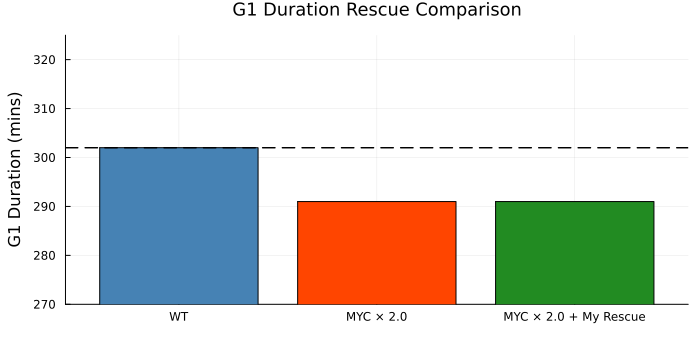

In [5]:
# Exercise 1: Edit rescue_mods below to restore WT-like G1 duration (302 min) in a MYC × 2.0 cell!
test_myc    = 2.0
rescue_name = "MYC × 2.0 + My Rescue"
rescue_mods = Dict{String, Float64}()   # <-- Try Dict("k1_GMprod" => 0.85), Dict("k2_5" => 1.5), or Dict("k2_9" => 0.6)

res_wt     = run_cell_cycle(1.0)
res_mut    = run_cell_cycle(test_myc)
res_rescue = run_cell_cycle(test_myc; mods=rescue_mods)

rows = [
    ("WT",                            res_wt.phases),
    ("MYC × $(test_myc) (untreated)", res_mut.phases),
    (rescue_name,                     res_rescue.phases),
]

display(DataFrame(
    Condition = [r[1] for r in rows],
    G1        = [r[2].G1 for r in rows],
    S         = [r[2].S  for r in rows],
    G2        = [r[2].G2 for r in rows],
    M         = [r[2].M  for r in rows],
    Total     = [r[2].total for r in rows],
    Status    = [r[2].arrested ? "Arrested" : "Cycling" for r in rows],
))

if !res_rescue.phases.arrested
    p_bar = bar(
        ["WT", "MYC × $(test_myc)", rescue_name],
        [res_wt.phases.G1, res_mut.phases.G1, res_rescue.phases.G1];
        fillcolor=[:steelblue, :orangered, :forestgreen],
        legend=false,
        ylabel="G1 Duration (mins)",
        title="G1 Duration Rescue Comparison", titlefontsize=12,
        ylims=(270, max(325, res_rescue.phases.G1 + 10)),
        size=(700, 340),
    )
    hline!(p_bar, [res_wt.phases.G1], linestyle=:dash, color=:black, lw=1.5)
    p_bar
else
    println("Your perturbation arrested the cell cycle! Try a gentler multiplier (closer to 1.0) to restore WT G1 speed without total arrest.")
end

````{admonition} Hint
:class: dropdown tip

Try comparing:
- `Dict("k1_GMprod" => 0.85)` — directly counteracts c-MYC's boost to growth machinery (`GM`)
- `Dict("k2_5" => 1.5)` — over-expresses the G1/S brake **p27 (`CDKN1B`)**
- `Dict("k2_9" => 0.6)` or `Dict("k1_20" => 0.6)` — mimics clinical **CDK4/6 inhibition** (palbociclib) on the Cyclin D–RB1 axis
- Also try `Dict("k2_29" => 0.7)` (CycA) and check how all four phase columns (`G1`, `S`, `G2`, `M`) respond!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
test_myc = 2.0
candidates = [
    ("WT",                       1.0,      Dict{String, Float64}()),
    ("MYC × 2 (untreated)",      test_myc, Dict{String, Float64}()),
    ("+ GM inh (0.85×)",         test_myc, Dict("k1_GMprod" => 0.85)),
    ("+ p27 OE (1.5×)",          test_myc, Dict("k2_5" => 1.5)),
    ("+ CycD inh (0.6×)",        test_myc, Dict("k2_9" => 0.6)),
    ("+ RB-phos / CDK4/6 (0.6×)",test_myc, Dict("k1_20" => 0.6)),
    ("+ CycA inh (0.7×)",        test_myc, Dict("k2_29" => 0.7)),
]

out_df = DataFrame(Condition=String[], G1=Float64[], S=Float64[], G2=Float64[], M=Float64[], Total=Float64[], Status=String[])
for (name, m, d) in candidates
    ph = run_cell_cycle(m; mods=d).phases
    push!(out_df, (name, ph.G1, ph.S, ph.G2, ph.M, ph.total, ph.arrested ? "Arrested" : "Cycling"))
end
display(out_df)

cycling = filter(r -> r.Status == "Cycling", out_df)
p_sol = bar(
    cycling.Condition, cycling.G1;
    xrotation=25, legend=false, fillcolor=:purple, alpha=0.8,
    ylabel="G1 Duration (mins)", title="Candidate Rescues for MYC × 2.0", titlefontsize=12,
    ylims=(270, max(325, maximum(cycling.G1) + 10)), size=(780, 380),
)
hline!(p_sol, [out_df.G1[1]], linestyle=:dash, color=:black, lw=1.8)
p_sol
```

- Modestly reducing growth machinery (`"k1_GMprod" => 0.85`) restores wild-type G1 timing almost exactly (`302 min`, total `730 min`).
- Stronger G1 checkpoint braking — boosting **p27** (`"k2_5" => 1.5` → `515 min`) or inhibiting **Cyclin D** / **RB phosphorylation** (`"k2_9" => 0.6` → `1614 min`, `"k1_20" => 0.6` → `1515 min`, mimicking palbociclib) — dramatically extends G1 while leaving **S**, **G2**, and **M** nearly unchanged; pushing those inhibitors further arrests the cell cycle altogether.
````

---

## Summary & Looking Ahead to Multiscale Modelling

You have now recreated **both single-cell fate panels** from Figure 1 of *Norris et al.* (*Blood Cancer Journal*, 2024):
- **Apoptosis (`BCL2` scan, Figure 1B):** Overexpressing **BCL2** delays and then blocks MOMP and PARP cleavage, producing an anti-apoptotic (**AA**) phenotype that can be countered by targeting the mitochondrial BCL2/BAX balance (e.g. venetoclax).
- **Cell Cycle (`c-MYC` scan, Figure 1E):** Overexpressing **c-MYC** accelerates growth machinery (`GM`) and specifically shortens **G1**, producing a pro-proliferative (**PP**) phenotype sensitive to G1/S brakes (`p27`, `Cyclin D`/CDK4/6–`RB1`).

:::{tip} Next Up (Tutorial 6 — Multiscale Modelling)
Continue to **[Tutorial 6: From Separate Modules to One Dividing, Dying Cell](../tutorial-6/01-building-a-dividing-dying-cell.ipynb)** to combine **NF-κB**, **apoptosis**, **cell cycle**, and **differentiation** inside a full **193-species agent-based multiscale model** and recreate **Figure 2** of *Norris et al.* (MYC + BCL2 vs MYC + BCL6 Double-Hit Lymphoma)!
:::